In [1]:
#Import Libraries
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
#load the dataset
import pandas as pd

df = pd.read_csv("/content/archive.zip")

print(df.head())

                                            Document    Topic_group
0  connection with icon icon dear please setup ic...       Hardware
1  work experience user work experience user hi w...         Access
2  requesting for meeting requesting meeting hi p...       Hardware
3  reset passwords for external accounts re expir...         Access
4  mail verification warning hi has got attached ...  Miscellaneous


In [3]:
#check dataset info
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(47837, 2)

Column Names:
['Document', 'Topic_group']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Document     47837 non-null  object
 1   Topic_group  47837 non-null  object
dtypes: object(2)
memory usage: 747.6+ KB

Missing Values:
Document       0
Topic_group    0
dtype: int64


In [4]:
# check the ticket categories
print("Unique Ticket Categories:")
print(df["Topic_group"].unique())

print("\nNumber of Tickets in Each Category:")
print(df["Topic_group"].value_counts())


Unique Ticket Categories:
['Hardware' 'Access' 'Miscellaneous' 'HR Support' 'Purchase'
 'Administrative rights' 'Storage' 'Internal Project']

Number of Tickets in Each Category:
Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64


In [5]:
# Clean the Ticket Text
import re

def clean_text(text):
    text = str(text).lower()  # Convert to lowercase
    text = re.sub(r"http\S+|www\S+", "", text)  # Remove URLs
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)  # Remove special symbols
    text = re.sub(r"\s+", " ", text).strip()  # Remove extra spaces
    return text

# Create a cleaned text column
df["Cleaned_Document"] = df["Document"].apply(clean_text)

print("Text cleaning completed successfully!")

# Display original and cleaned text
display(df[["Document", "Cleaned_Document", "Topic_group"]].head())


Text cleaning completed successfully!


,Document,Cleaned_Document,Topic_group
0,connection with icon icon dear please setup ic...,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,mail verification warning hi has got attached ...,Miscellaneous


In [7]:
#Separate Input and Output
X = df["Cleaned_Document"].fillna("").astype(str)
y = df["Topic_group"]

print("Input data shape:", X.shape)
print("Output data shape:", y.shape)

print("\nSample input:")
print(X.iloc[0])

print("\nSample output:")
print(y.iloc[0])

Input data shape: (47837,)
Output data shape: (47837,)

Sample input:
connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead

Sample output:
Hardware


In [8]:
# Split Training Data and Testing Data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 38269
Testing records: 9568


In [9]:
#Convert Text into Numbers (TF-IDF)
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)
print("Text converted into numerical features successfully!")


Training data shape: (38269, 10000)
Testing data shape: (9568, 10000)
Text converted into numerical features successfully!


In [10]:
#Train the Machine Learning Model
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(X_train_tfidf, y_train)

print("Support Ticket Classification model trained successfully!")


Support Ticket Classification model trained successfully!


In [11]:
# Check Model Accuracy
# Predict categories for test data
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed performance report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 85.2 %

Classification Report:
                       precision    recall  f1-score   support

               Access       0.90      0.89      0.89      1425
Administrative rights       0.68      0.87      0.76       352
           HR Support       0.89      0.84      0.86      2183
             Hardware       0.86      0.80      0.83      2724
     Internal Project       0.78      0.93      0.85       424
        Miscellaneous       0.79      0.87      0.83      1412
             Purchase       0.92      0.90      0.91       493
              Storage       0.85      0.92      0.89       555

             accuracy                           0.85      9568
            macro avg       0.84      0.88      0.85      9568
         weighted avg       0.86      0.85      0.85      9568



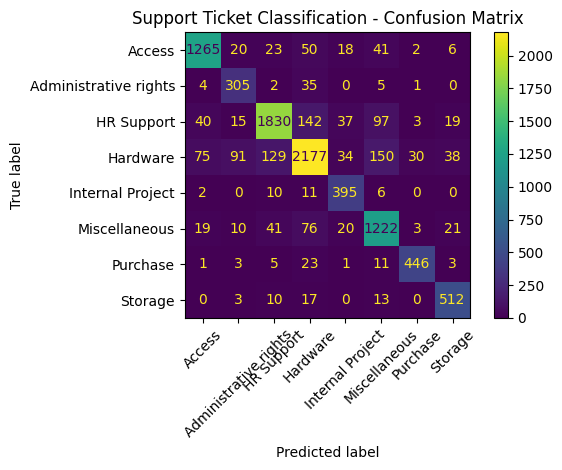

In [12]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

display_matrix.plot(xticks_rotation=45)
plt.title("Support Ticket Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
#Test a New Support Ticket
# New support ticket
new_ticket = ["My computer is not working properly"]

# Convert text using the trained TF-IDF vectorizer
new_ticket_tfidf = tfidf.transform(new_ticket)

# Predict the ticket category
prediction = model.predict(new_ticket_tfidf)

print("New Ticket:", new_ticket[0])
print("Predicted Category:", prediction[0])

New Ticket: My computer is not working properly
Predicted Category: Hardware


In [14]:
#Create Priority Logic
def assign_priority(text):
    text = str(text).lower()

    high_keywords = [
        "urgent",
        "critical",
        "system down",
        "server down",
        "security breach",
        "data loss",
        "production down"
    ]

    medium_keywords = [
        "unable to access",
        "not working",
        "error",
        "failed",
        "problem",
        "issue",
        "cannot access"
    ]

    if any(keyword in text for keyword in high_keywords):
        return "High"

    elif any(keyword in text for keyword in medium_keywords):
        return "Medium"

    else:
        return "Low"


print(assign_priority("URGENT! Production server is down"))
print(assign_priority("Unable to access my work account"))
print(assign_priority("Request for general information"))


High
Medium
Low


In [15]:
# Assign Priority to All Tickets
# Assign priority to every ticket
df["Priority"] = df["Document"].apply(assign_priority)

# Display sample tickets
print("Sample Tickets with Category and Priority:")

display(df[["Document", "Topic_group", "Priority"]].head(10))

# Count tickets in each priority level
print("\nPriority Distribution:")
print(df["Priority"].value_counts())


Sample Tickets with Category and Priority:


,Document,Topic_group,Priority
0,connection with icon icon dear please setup ic...,Hardware,Low
1,work experience user work experience user hi w...,Access,Low
2,requesting for meeting requesting meeting hi p...,Hardware,Low
3,reset passwords for external accounts re expir...,Access,Medium
4,mail verification warning hi has got attached ...,Miscellaneous,Low
5,mail please dear looks blacklisted receiving m...,Miscellaneous,Low
6,prod servers tunneling prod tunneling va la tu...,Hardware,Medium
7,access request dear modules report report cost...,HR Support,Low
8,reset passwords for our client and passwords c...,Access,Low
9,direct reports missing time please action repo...,HR Support,Low



Priority Distribution:
Priority
Low       34194
Medium    11942
High       1701
Name: count, dtype: int64


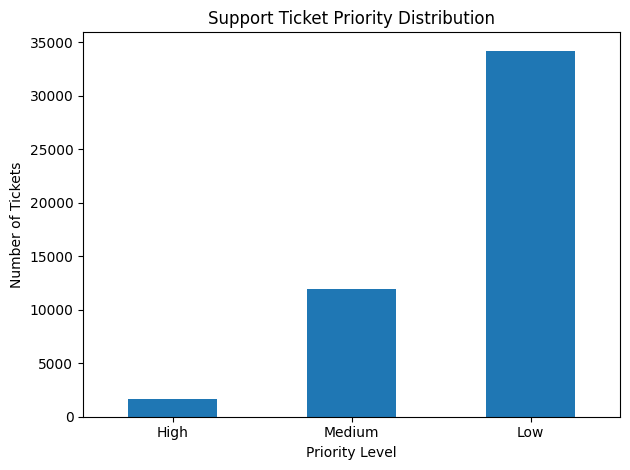

In [16]:
# Visualize Priority Distribution
import matplotlib.pyplot as plt

priority_counts = df["Priority"].value_counts().reindex(
    ["High", "Medium", "Low"],
    fill_value=0
)

priority_counts.plot(kind="bar")

plt.title("Support Ticket Priority Distribution")
plt.xlabel("Priority Level")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
# Build the Final Ticket Prediction System
def predict_ticket(ticket_text):
    # Clean the new ticket
    cleaned_ticket = clean_text(ticket_text)

    # Predict ticket category
    ticket_features = tfidf.transform([cleaned_ticket])
    predicted_category = model.predict(ticket_features)[0]

    # Assign priority using our rules
    predicted_priority = assign_priority(ticket_text)

    return predicted_category, predicted_priority


# Test with a new ticket
ticket = "URGENT! The production server is down and users cannot work."

category, priority = predict_ticket(ticket)

print("Ticket:", ticket)
print("Predicted Category:", category)
print("Assigned Priority:", priority)

Ticket: URGENT! The production server is down and users cannot work.
Predicted Category: Hardware
Assigned Priority: High


In [18]:
# finale testing
test_tickets = [
    "URGENT! The production server is down",
    "I cannot access my work account",
    "I need general information about the service"
]

for ticket in test_tickets:
    category, priority = predict_ticket(ticket)

    print("Ticket:", ticket)
    print("Predicted Category:", category)
    print("Assigned Priority:", priority)
    print("-" * 50)


Ticket: URGENT! The production server is down
Predicted Category: Hardware
Assigned Priority: High
--------------------------------------------------
Ticket: I cannot access my work account
Predicted Category: Access
Assigned Priority: Medium
--------------------------------------------------
Ticket: I need general information about the service
Predicted Category: Miscellaneous
Assigned Priority: Low
--------------------------------------------------
